In [1]:
!wget -q http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip
!wget -q http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip
!unzip -q DIV2K_train_HR.zip -d data/
!unzip -q DIV2K_valid_HR.zip -d data/
!rm DIV2K_train_HR.zip DIV2K_valid_HR.zip

In [3]:
!pip install lpips
import os
import random
from pathlib import Path

import cv2
import lpips
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from skimage.restoration import richardson_lucy
from torch.utils.data import DataLoader, Dataset
from torchvision.models import VGG16_Weights, vgg16

from models import ResidualUNet

In [4]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

PROJECT_DIR = Path.cwd()
PROJECT_DIR = Path(PROJECT_DIR)
TRAIN_DIR = PROJECT_DIR / "data" / "DIV2K_train_HR"
VALID_DIR = PROJECT_DIR / "data" / "DIV2K_valid_HR"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
CROP_SIZE = 256
KERNEL_SIGMA = {3: 1.0, 5: 1.5}
KERNEL_SIZES = (3, 5)
BATCH_SIZE = 4
EPOCHS = 10
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-4
PERCEPTUAL_WEIGHT = 0.1
RICHARDSON_LUCY_ITERATIONS = 30
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
NUM_WORKERS = 0

print(f"Device: {DEVICE}")
print(f"Project Directory: {PROJECT_DIR}")
print(f"Gaussian blur sigmas: {KERNEL_SIGMA}")

Device: cuda
Project Directory: /content
Gaussian blur sigmas: {3: 1.0, 5: 1.5}


In [5]:
class DIV2KDeblurDataset(Dataset):
    def __init__(self, image_dir, crop_size=256, fixed_kernel=None, training=False):
        self.image_paths = sorted(
            path
            for path in Path(image_dir).iterdir()
            if path.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
        )
        self.crop_size = crop_size
        self.fixed_kernel = fixed_kernel
        self.training = training

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = cv2.imread(str(self.image_paths[index]), cv2.IMREAD_COLOR)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        height, width = image.shape[:2]
        if self.training:
            top = random.randint(0, height - self.crop_size)
            left = random.randint(0, width - self.crop_size)
        else:
            top = (height - self.crop_size) // 2
            left = (width - self.crop_size) // 2
        image = image[top:top + self.crop_size, left:left + self.crop_size]
        sharp = image.astype(np.float32) / 255.0
        kernel_size = self.fixed_kernel
        if kernel_size is None:
            kernel_size = random.choice(KERNEL_SIZES)
        blurred = cv2.GaussianBlur(
            sharp,
            (kernel_size, kernel_size),
            sigmaX=KERNEL_SIGMA[kernel_size],
            sigmaY=KERNEL_SIGMA[kernel_size],
            borderType=cv2.BORDER_REFLECT101,
        )
        sharp_tensor = torch.from_numpy(np.ascontiguousarray(sharp.transpose(2, 0, 1)))
        blurred_tensor = torch.from_numpy(np.ascontiguousarray(blurred.transpose(2, 0, 1)))
        return blurred_tensor, sharp_tensor


train_dataset = DIV2KDeblurDataset(TRAIN_DIR, crop_size=CROP_SIZE, training=True)
validation_datasets = {
    kernel_size: DIV2KDeblurDataset(VALID_DIR, crop_size=CROP_SIZE, fixed_kernel=kernel_size)
    for kernel_size in KERNEL_SIZES
}
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=DEVICE.type == "cuda",
    drop_last=True,
)
validation_loaders = {
    kernel_size: DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=DEVICE.type == "cuda",
    )
    for kernel_size, dataset in validation_datasets.items()
}

sample_blurred, sample_sharp = train_dataset[0]
assert sample_blurred.shape == (3, CROP_SIZE, CROP_SIZE)
assert sample_sharp.min() >= 0.0 and sample_sharp.max() <= 1.0
assert sample_blurred.min() >= 0.0 and sample_blurred.max() <= 1.0
blur_difference = torch.mean(torch.abs(sample_blurred - sample_sharp)).item()
assert blur_difference > 1e-3
print(f"Training images: {len(train_dataset)}; validation images per blur kernel: {len(validation_datasets[3])}")
print(f"Mean absolute blur difference: {blur_difference:.4f}")

Training images: 800; validation images per blur kernel: 100
Mean absolute blur difference: 0.0094


In [6]:
model = ResidualUNet().to(DEVICE)

print(f"ResidualUNet parameters: {sum(parameter.numel() for parameter in model.parameters()):,}")

ResidualUNet parameters: 535,827


In [7]:
class VGGPerceptualLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(*list(vgg16(weights=VGG16_Weights.DEFAULT).features.children())[:16])
        self.features.eval()
        for parameter in self.features.parameters():
            parameter.requires_grad = False
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, prediction, target):
        prediction = (prediction - self.mean) / self.std
        target = (target - self.mean) / self.std
        return nn.functional.l1_loss(self.features(prediction), self.features(target))


perceptual_loss = VGGPerceptualLoss().to(DEVICE)
pixel_loss = nn.L1Loss()


def combined_loss(prediction, target):
    return pixel_loss(prediction, target) + PERCEPTUAL_WEIGHT * perceptual_loss(prediction, target)


print("VGG16 perceptual loss is ready")

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:05<00:00, 94.0MB/s]


VGG16 perceptual loss is ready


In [8]:
def validation_loss(model):
    model.eval()
    total_loss = 0.0
    total_images = 0
    with torch.no_grad():
        for loader in validation_loaders.values():
            for blurred, sharp in loader:
                blurred = blurred.to(DEVICE)
                sharp = sharp.to(DEVICE)
                loss = combined_loss(model(blurred), sharp)
                total_loss += loss.item() * blurred.size(0)
                total_images += blurred.size(0)
    return total_loss / total_images


def train_one_model(model, model_name):
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )
    best_loss = float("inf")
    history = []
    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0.0
        total_images = 0
        for blurred, sharp in train_loader:
            blurred = blurred.to(DEVICE)
            sharp = sharp.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction = model(blurred)
            loss = combined_loss(prediction, sharp)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * blurred.size(0)
            total_images += blurred.size(0)
        mean_train_loss = total_loss / total_images
        mean_validation_loss = validation_loss(model)
        history.append({"train_loss": mean_train_loss, "validation_loss": mean_validation_loss})
        if mean_validation_loss < best_loss:
            best_loss = mean_validation_loss
            torch.save(model.state_dict(), CHECKPOINT_DIR / f"{model_name}_best.pth")
        print(
            f"{model_name} epoch {epoch + 1}/{EPOCHS}: "
            f"train={mean_train_loss:.5f}, validation={mean_validation_loss:.5f}"
        )
    model.load_state_dict(torch.load(CHECKPOINT_DIR / f"{model_name}_best.pth", map_location=DEVICE, weights_only=True))
    return history


In [10]:
model_history = train_one_model(model, "residual_unet")

residual_unet epoch 1/10: train=0.06642, validation=0.08098
residual_unet epoch 2/10: train=0.06343, validation=0.07930
residual_unet epoch 3/10: train=0.06111, validation=0.07790
residual_unet epoch 4/10: train=0.06137, validation=0.07691
residual_unet epoch 5/10: train=0.06128, validation=0.07605
residual_unet epoch 6/10: train=0.05930, validation=0.07531
residual_unet epoch 7/10: train=0.05652, validation=0.07495
residual_unet epoch 8/10: train=0.05817, validation=0.07378
residual_unet epoch 9/10: train=0.05723, validation=0.07335
residual_unet epoch 10/10: train=0.05854, validation=0.07291


In [11]:
def build_gaussian_psf(kernel_size, sigma):
    gaussian_1d = cv2.getGaussianKernel(kernel_size, sigma).astype(np.float64)
    psf = gaussian_1d @ gaussian_1d.T
    return psf / psf.sum()


def apply_richardson_lucy(blurred_rgb, kernel_size):
    psf = build_gaussian_psf(kernel_size, KERNEL_SIGMA[kernel_size])
    channels = [
        richardson_lucy(
            blurred_rgb[:, :, channel].astype(np.float64),
            psf,
            num_iter=RICHARDSON_LUCY_ITERATIONS,
            clip=True,
        )
        for channel in range(3)
    ]
    return np.clip(np.stack(channels, axis=-1), 0.0, 1.0).astype(np.float32)


for kernel_size in KERNEL_SIZES:
    psf = build_gaussian_psf(kernel_size, KERNEL_SIGMA[kernel_size])
    assert psf.shape == (kernel_size, kernel_size)
    assert np.isclose(psf.sum(), 1.0)
print("Gaussian PSFs are normalized and match the degradation kernels")

Gaussian PSFs are normalized and match the degradation kernels


In [12]:
lpips_model = lpips.LPIPS(net="alex").to(DEVICE).eval()
for parameter in lpips_model.parameters():
    parameter.requires_grad = False


def calculate_lpips(prediction, target):
    prediction_tensor = torch.from_numpy(prediction.transpose(2, 0, 1)).unsqueeze(0).to(DEVICE)
    target_tensor = torch.from_numpy(target.transpose(2, 0, 1)).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        value = lpips_model(prediction_tensor * 2.0 - 1.0, target_tensor * 2.0 - 1.0)
    return float(value.mean().item())


def calculate_metrics(prediction, target):
    prediction = np.clip(prediction, 0.0, 1.0)
    target = np.clip(target, 0.0, 1.0)
    return {
        "PSNR": peak_signal_noise_ratio(target, prediction, data_range=1.0),
        "SSIM": structural_similarity(target, prediction, channel_axis=-1, data_range=1.0),
        "LPIPS": calculate_lpips(prediction.astype(np.float32), target.astype(np.float32)),
    }


NUM_VISUAL_SAMPLES = 3
models = {"residual_unet": model}
results = {}
# pick fresh random indices each run so the visual comparison isn't always the same images
visual_sample_indices = {
    kernel_size: set(random.sample(range(len(dataset)), min(NUM_VISUAL_SAMPLES, len(dataset))))
    for kernel_size, dataset in validation_datasets.items()
}
visual_samples = {kernel_size: [] for kernel_size in KERNEL_SIZES}

for kernel_size, loader in validation_loaders.items():
    method_totals = {
        method: {"PSNR": 0.0, "SSIM": 0.0, "LPIPS": 0.0, "count": 0}
        for method in ("richardson_lucy", "residual_unet")
    }
    global_index = 0
    for blurred_batch, sharp_batch in loader:
        model_predictions = {}
        blurred_device = blurred_batch.to(DEVICE)
        with torch.no_grad():
            for method, method_model in models.items():
                method_model.eval()
                model_predictions[method] = method_model(blurred_device).cpu().numpy().transpose(0, 2, 3, 1)
        blurred_images = blurred_batch.numpy().transpose(0, 2, 3, 1)
        sharp_images = sharp_batch.numpy().transpose(0, 2, 3, 1)
        for batch_index, (blurred_image, sharp_image) in enumerate(zip(blurred_images, sharp_images)):
            predictions = {
                "richardson_lucy": apply_richardson_lucy(blurred_image, kernel_size),
                "residual_unet": model_predictions["residual_unet"][batch_index],
            }
            for method, prediction in predictions.items():
                image_metrics = calculate_metrics(prediction, sharp_image)
                for metric_name, metric_value in image_metrics.items():
                    method_totals[method][metric_name] += metric_value
                method_totals[method]["count"] += 1
            if global_index in visual_sample_indices[kernel_size]:
                visual_samples[kernel_size].append({
                    "input": blurred_image,
                    "ground_truth": sharp_image,
                    **predictions,
                })
            global_index += 1
    for method, totals in method_totals.items():
        count = totals.pop("count")
        results[f"{method}_gaussian_blur_{kernel_size}x{kernel_size}"] = {
            metric_name: totals[metric_name] / count
            for metric_name in ("PSNR", "SSIM", "LPIPS")
        }

print(f"Evaluated {len(results)} method/kernel combinations")

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 155MB/s] 


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth
Evaluated 4 method/kernel combinations


In [13]:
table_lines = [
    "| Method | PSNR (dB) | SSIM | LPIPS |",
    "|---|---:|---:|---:|",
]
for key, metrics in results.items():
    table_lines.append(
        f"| {key} | {metrics['PSNR']:.4f} | {metrics['SSIM']:.4f} | {metrics['LPIPS']:.4f} |"
    )
metrics_markdown = "\n".join(table_lines)
print(metrics_markdown)
(RESULTS_DIR / "metrics.md").write_text(metrics_markdown + "\n", encoding="utf-8")

| Method | PSNR (dB) | SSIM | LPIPS |
|---|---:|---:|---:|
| richardson_lucy_gaussian_blur_3x3 | 20.7536 | 0.9163 | 0.1891 |
| residual_unet_gaussian_blur_3x3 | 34.5108 | 0.9570 | 0.0409 |
| richardson_lucy_gaussian_blur_5x5 | 19.9922 | 0.8231 | 0.3480 |
| residual_unet_gaussian_blur_5x5 | 28.2758 | 0.8375 | 0.2367 |


319

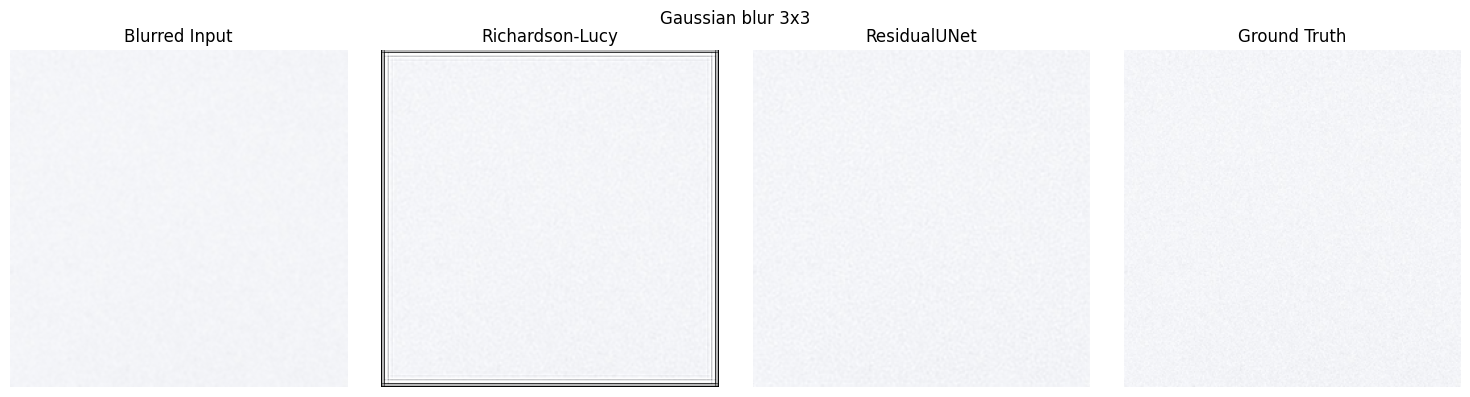

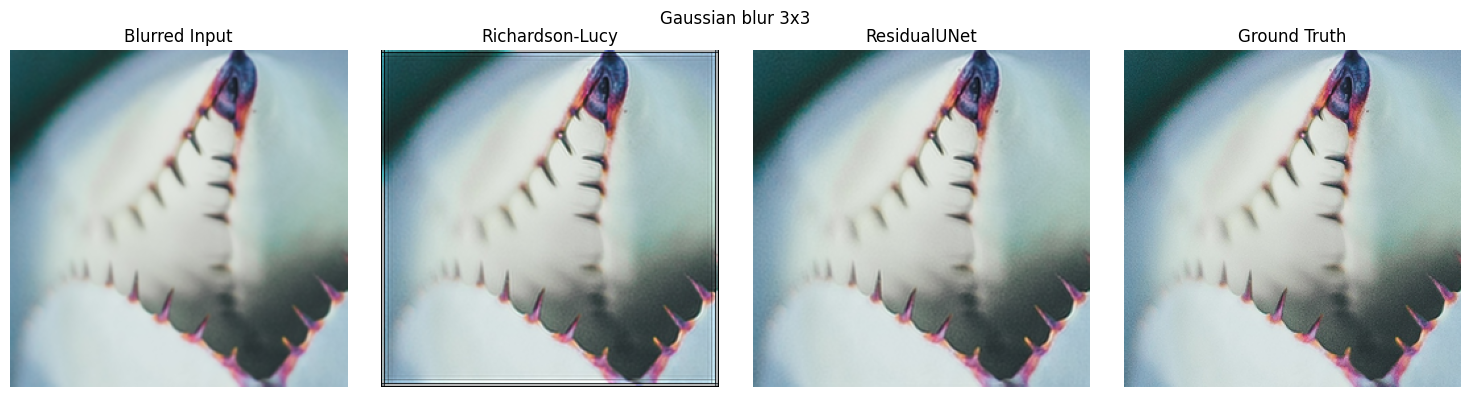

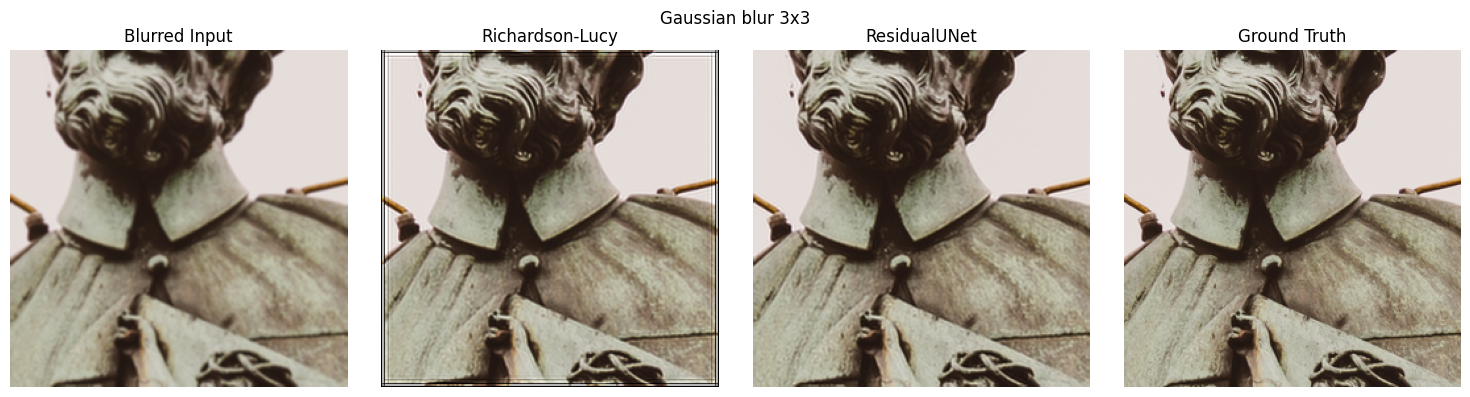

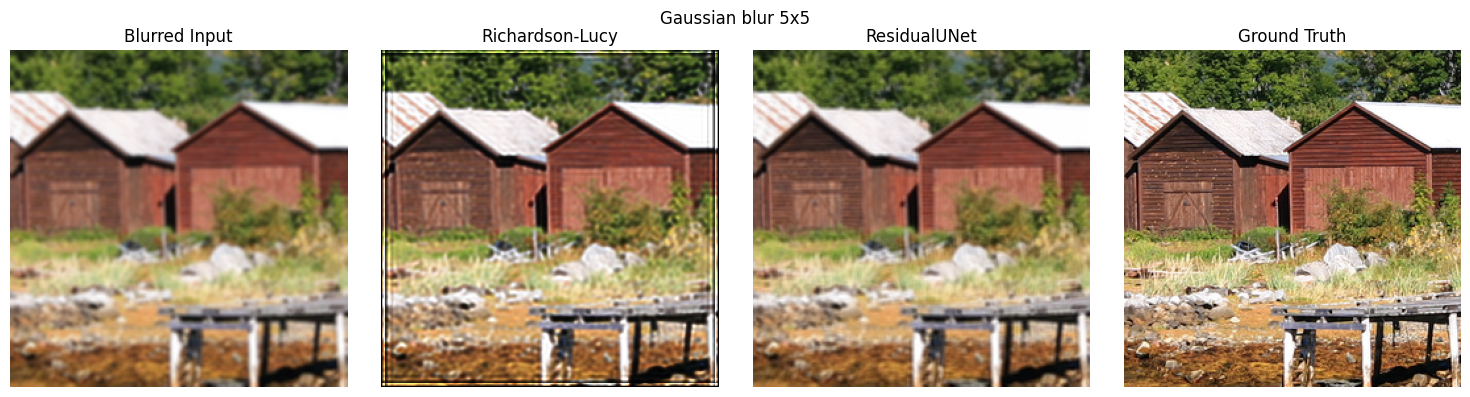

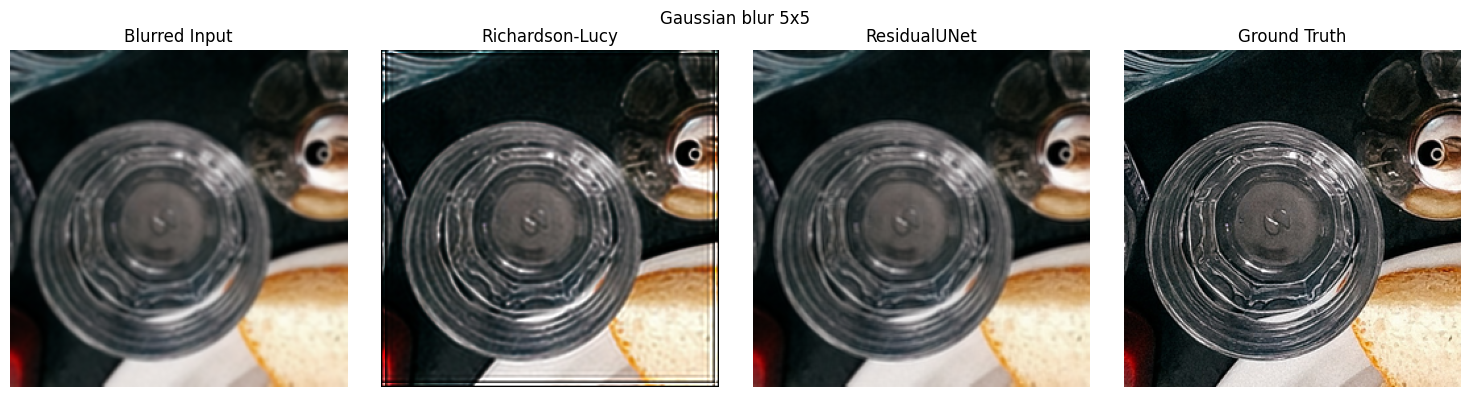

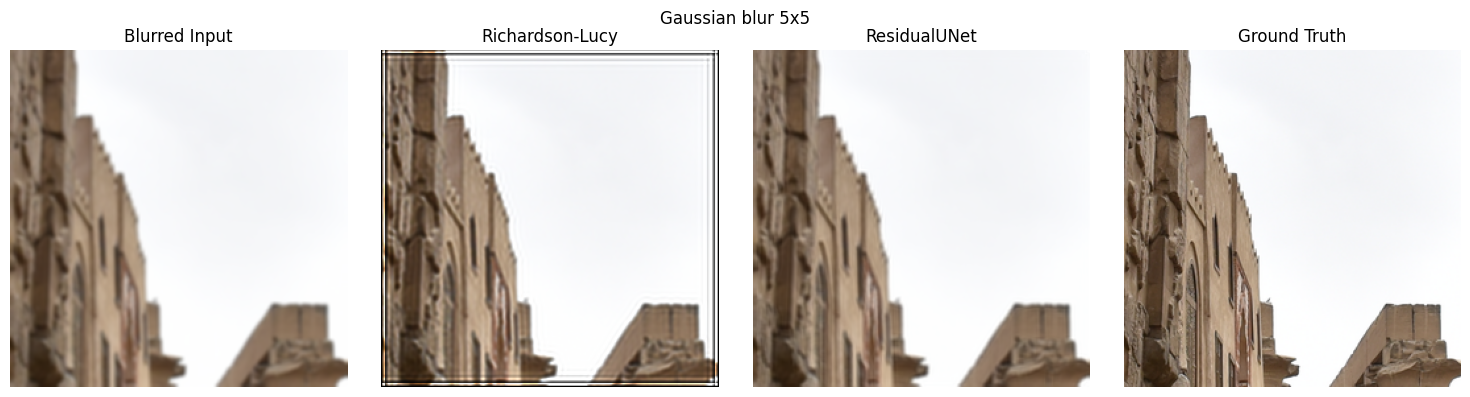

Saved 6 comparison figures


In [16]:
panel_titles = ["Blurred Input", "Richardson-Lucy", "ResidualUNet", "Ground Truth"]
panel_keys = ["input", "richardson_lucy", "residual_unet", "ground_truth"]
comparison_index = 0
for kernel_size, samples in visual_samples.items():
    for sample in samples:
        figure, axes = plt.subplots(1, 4, figsize=(15, 4))
        for axis, title, key in zip(axes, panel_titles, panel_keys):
            axis.imshow(np.clip(sample[key], 0.0, 1.0))
            axis.set_title(title)
            axis.axis("off")
        figure.suptitle(f"Gaussian blur {kernel_size}x{kernel_size}")
        figure.tight_layout()
        figure.savefig(FIGURES_DIR / f"comparison_{comparison_index + 1}.png", dpi=150, bbox_inches="tight")
        plt.show()
        plt.close(figure)
        comparison_index += 1

print(f"Saved {comparison_index} comparison figures")